In [52]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os

In [53]:
load_dotenv()

model = os.getenv('GROQ_MODEL')
api_key = os.getenv('GROQ_API_KEY')

In [54]:
llm = ChatGroq(model=model, api_key=api_key)

In [55]:
from pydantic import BaseModel
from langgraph.graph import START, END, StateGraph

In [56]:
class State(BaseModel):
    title:str = ""
    story:str = ""

In [57]:
def write_story(state:State):
    """Using LLM to write a short story on title"""
    res = llm.invoke(f"Write a short 10 - 15 words story on title: {state.title}")
    state.story = res.content

    return state

In [58]:
graph = StateGraph(State)
graph.add_node("story_node",write_story)

graph.add_edge(START, "story_node")
graph.add_edge("story_node", END)

app = graph.compile()

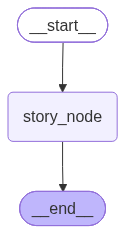

In [59]:
app

In [60]:
res = app.invoke({"title":"Sky is Blue"})
res['story']

'**Title: Sky is Blue**\n\nSky is Blue, but midnight stars argued, claiming night was their canvas.'

In [61]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage
from typing import Annotated

In [62]:
class ChatState(BaseModel):
    messages: Annotated[list, add_messages] = []

In [63]:
def llm1(state:ChatState):
    res = llm.invoke(state.messages)
    state.messages = res
    return state

def llm2(state:ChatState):
    res = llm.invoke(state.messages)
    state.messages = res
    return state

def llm3(state:ChatState):
    res = llm.invoke(state.messages)
    state.messages = res
    return state

In [64]:
graph = StateGraph(ChatState)

graph.add_node("llm1", llm1)
graph.add_node("llm2", llm2)
graph.add_node("llm3", llm3)

graph.add_edge(START, "llm1")
graph.add_edge("llm1", "llm2")
graph.add_edge("llm2", "llm3")
graph.add_edge("llm3", END)

app = graph.compile()

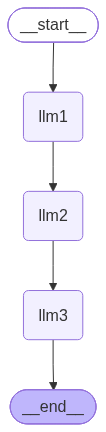

In [65]:
app

In [66]:
res = app.invoke({'messages':[HumanMessage("Hello")]})
res["messages"]

[HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='d6b7e1eb-5e3d-4f1b-84a9-f60369f9fda2'),
 AIMessage(content='Hello! 👋 How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond to user greeting. Provide friendly greeting, ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 72, 'total_tokens': 110, 'completion_time': 0.040920037, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.003441391, 'prompt_tokens_details': None, 'queue_time': 0.406305457, 'total_time': 0.044361428}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d23c14756c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13c1e-1788-7bd3-bc37-b325de92eb2f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 38, 'total_tokens': 110, 'output_token_details': {'reasoning': 18}}),
 AIMe

In [85]:
def custom_reducer(existing:str, new:str):
    return f"{existing} {new}"

In [86]:
class AppendState(BaseModel):
    sentence:Annotated[str, custom_reducer] = ""

In [87]:
def word1(state:AppendState):
    word = "Hello"
    state.sentence = word
    return state

def word2(state:AppendState):
    word = "Vansh"
    state.sentence = word
    return state

def word3(state:AppendState):
    word = "How are you"
    state.sentence = word
    return state

In [88]:
graph = StateGraph(AppendState)

graph.add_node("word1", word1)
graph.add_node("word2", word2)
graph.add_node("word3", word3)

graph.add_edge(START, "word1")
graph.add_edge("word1", "word2")
graph.add_edge("word2", "word3")
graph.add_edge("word3", END)

app = graph.compile()

In [89]:
app.invoke({"sentence":"Me:"})

{'sentence': ' Me: Hello Vansh How are you'}